# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

current_dir = os.path.dirname(os.path.abspath("Incremental-Learning-MycroftMinds"))
parent_dir = os.path.dirname(current_dir)
# Insert the parent directory at the beginning of sys.path if it's not already there.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

## Import external libs and internal models

In [2]:
import time
from typing import Optional, Tuple, Dict, Any, List

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
#from river.drift.binary import DDM, EDDM
from src.bagging import ARFRegressorFODT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict
from src.evaluation.baseline import PreviousValueRegressor

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [4]:
HOURLY = True
DATA_FREQUENCY = 'H' if HOURLY else '5min'

In [5]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_hourly_wfv', use_numpy=True)
    features = ['time', 'device_id', 'hour', 'weekday', 'month', 
                 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                 'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                 'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = []

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(649, 43), y=(649,)
First valid split shape: X=(672, 43), y=(672,)

Memory usage:
Train: 6.26 MB
Valid: 1.41 MB
Test: 0.41 MB
Total: 8.08 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

## Hourly granularity

### Baseline model (predict previous value)

In [7]:
update_freq = "1H"
baseline = PreviousValueRegressor()

In [8]:
baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=baseline,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2535
	MAE: 0.1477
	MAPE: 17.4044%

Directional Metrics:
	Directional Accuracy: 36.0656%
	First-Diff Correlation: -0.0202

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3479
	MAE: 0.

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2578
	MAE: 0.1454
	MAPE: 23.4458%

Directional Metrics:
	Directional Accuracy: 38.3010%
	First-Diff Correlation: 0.2243

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3271
	MAE: 0.1

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2448
	MAE: 0.1448
	MAPE: 31.0642%

Directional Metrics:
	Directional Accuracy: 37.4069%
	First-Diff Correlation: -0.0210

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2440
	MAE: 0.

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1543
	MAE: 0.0696
	MAPE: 12.5644%

Directional Metrics:
	Directional Accuracy: 40.1274%
	First-Diff Correlation: 0.4616

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.7500
		Recall: 1.0000
		F1: 0.8571
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1261
	MAE: 0.0

#### Results

In [9]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2280 ± 0.0407
	MAE: 0.1290 ± 0.0296
	MAPE: 23.9570% ± 7.3836%

	Directional Metrics:
		Directional Accuracy: 39.3923% ± 4.6442%
		First-Diff Correlation: 0.1838 ± 0.1970

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8571 ± 0.3499
		Spike Recall: 0.8571 ± 0.3499
		Spike F1: 0.8571 ± 0.3499
		Drop Precision: 0.8139 ± 0.3429
		Drop Recall: 0.8571 ± 0.3499
		Drop F1: 0.8329 ± 0.3434
Daily Metrics:
	RMSE: 0.2624 ± 0.0673
	MAE: 0.1164 ± 0.0326
	MAPE: 1.3658% ± 0.2072%

	Directional Metrics:
		Directional Accuracy: 95.9184% ± 3.5348%
		First-Diff Correlation: 0.9995 ± 0.0003

	Immediate Detection (delta=0):


#### Validation plots

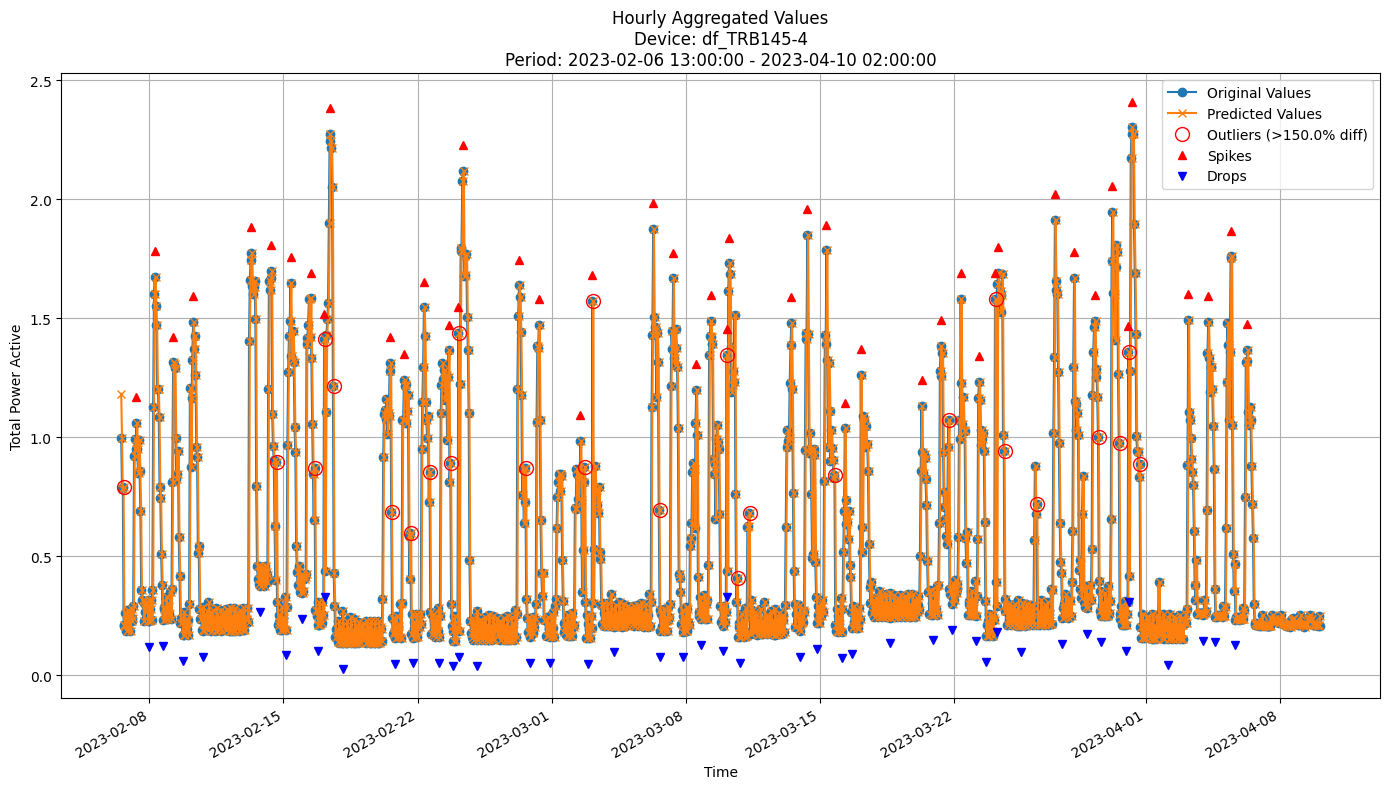


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2328
MAE: 0.1326
MAPE: 29.8567%

Directional Metrics:
Directional Accuracy: 36.8421%
First-Diff Correlation: -0.0120

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.9787
  Recall: 1.0000
  F1 Score: 0.9892


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [11]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.03,
    subsample=0.8,
    max_depth=10,
    random_state=42)

In [ ]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 1.41 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 2.05 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3575
	MAE: 0.2497
	MAPE: 31.6904%

Directional Metrics:
	Directional Accuracy: 56.0358%
	First-Diff Correlation: 0.2208

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 2.81 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 3.54 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3039
	MAE: 0.2046
	MAPE: 40.8759%

Directional Metrics:
	Directional Accuracy: 59.1654%
	First-Diff Correlation: 0.3749

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 8.87 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 9.67 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2344
	MAE: 0.1534
	MAPE: 35.1393%

Directional Metrics:
	Directional Accuracy: 53.3532%
	First-Diff Correlation: 0.3064

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1111
		Recall: 0.0870
		F1: 0.0976


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 10.55 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1705
	MAE: 0.1065
	MAPE: 29.9095%

Directional Metrics:
	Directional Accuracy: 59.2357%
	First-Diff Correlation: 0.3266

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.2500
		F1: 0.2222
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6000
		Recall: 0.7500
		F1: 0.6667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------

#### Results

In [13]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0497 ± 0.0106
	MAE: 0.0333 ± 0.0046
	MAPE: 7.4065% ± 1.1843%

	Directional Metrics:
		Directional Accuracy: 89.1446% ± 1.3532%
		First-Diff Correlation: 0.9760 ± 0.0145

	Immediate Detection (delta=0):
		Spike Precision: 0.8975 ± 0.1083
		Spike Recall: 0.7530 ± 0.1238
		Spike F1: 0.8056 ± 0.0634
		Drop Precision: 0.1479 ± 0.1372
		Drop Recall: 0.1522 ± 0.1389
		Drop F1: 0.1498 ± 0.1377

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9351 ± 0.0796
		Spike Recall: 0.7922 ± 0.1534
		Spike F1: 0.8439 ± 0.0813
		Drop Precision: 0.1652 ± 0.1574
		Drop Recall: 0.1697 ± 0.1588
		Drop F1: 0.1672 ± 0.1578
Daily Metrics:
	RMSE: 0.4566 ± 0.0575
	MAE: 0.3764 ± 0.0431
	MAPE: 3.4611% ± 0.3684%

	Directional Metrics:
		Directional Accuracy: 93.3766% ± 1.6407%
		First-Diff Correlation: 0.9995 ± 0.0003

	Immediate Detection (delta=0):
	

#### Feature importance
[WiP] Right now only for the last split and last device

In [14]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.5531829517537102)),
 ('L2_act_power_lag_1h', np.float64(0.07891330800039476)),
 ('hour', np.float64(0.07832269865487354)),
 ('L2_current_lag_1h', np.float64(0.05595649466475443)),
 ('L3_react_power_lag_1h', np.float64(0.04154862662622708)),
 ('month', np.float64(0.013196429149711796)),
 ('L1_act_power_lag_1h', np.float64(0.011640492147334635)),
 ('L2_app_power_lag_1h', np.float64(0.010445078743705958)),
 ('L1_react_power_lag_24h', np.float64(0.010338615524865489)),
 ('powerfactor3_lag_1h', np.float64(0.009574609878353792)),
 ('grid_freq_lag_1h', np.float64(0.008365237194251272)),
 ('L3_react_power_lag_24h', np.float64(0.007908025282131134)),
 ('L3_act_power_lag_1h', np.float64(0.007307952132196116)),
 ('powerfactor1_lag_1h', np.float64(0.006540603057063766)),
 ('L2_act_power_lag_24h', np.float64(0.0064285377110188426)),
 ('grid_freq_lag_24h', np.float64(0.0061780235094540115)),
 ('powerfactor2_lag_24h', np.float64(0.0061596331313278855)),
 ('powerfac

#### Training plots

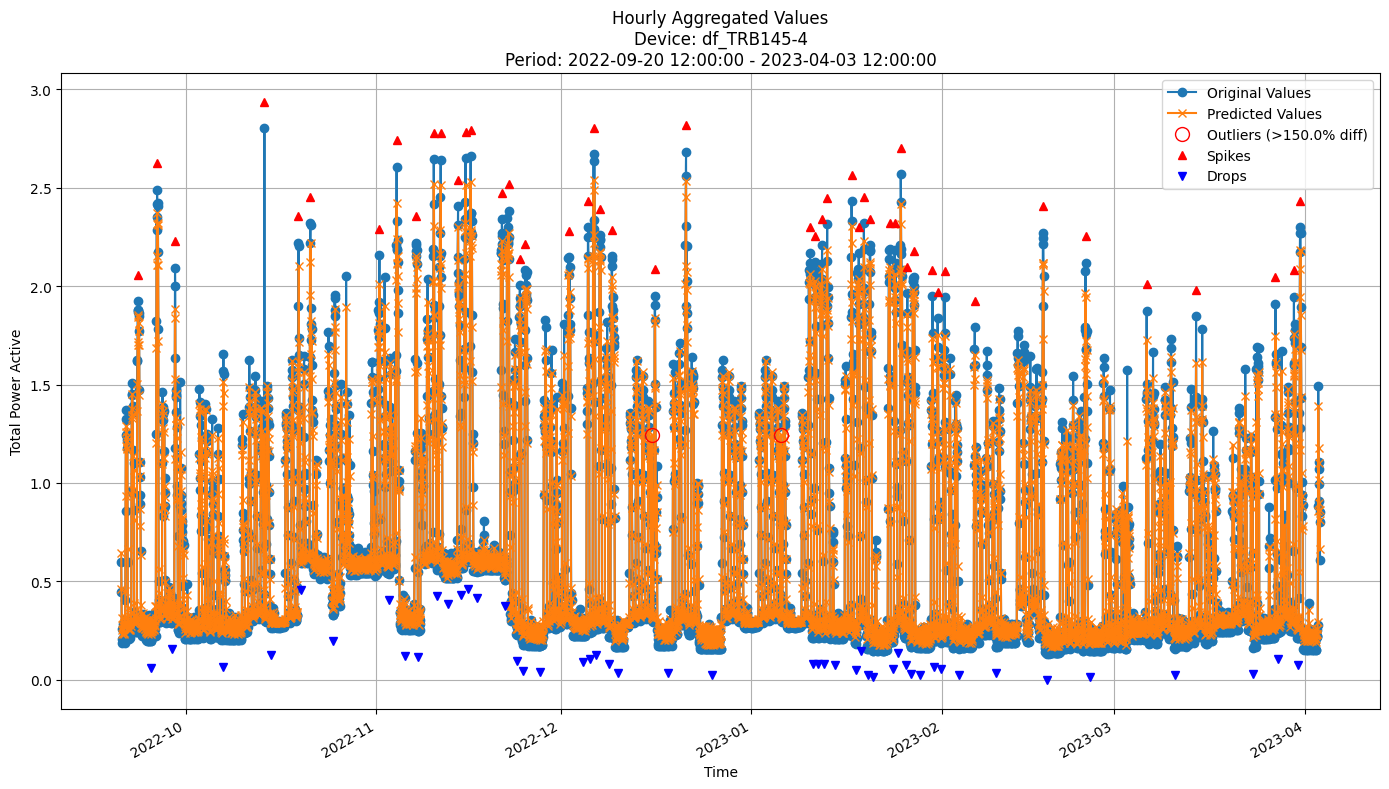


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0606
MAE: 0.0395
MAPE: 9.2928%

Directional Metrics:
Directional Accuracy: 86.6880%
First-Diff Correlation: 0.9631

Immediate Detection (delta=0):
Spikes:
  Precision: 0.6852
  Recall: 0.7551
  F1 Score: 0.7184
Drops:
  Precision: 0.2642
  Recall: 0.2917
  F1 Score: 0.2772

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7963
  Recall: 0.8776
  F1 Score: 0.8350
Drops:
  Precision: 0.2642
  Recall: 0.2917
  F1 Score: 0.2772


In [15]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

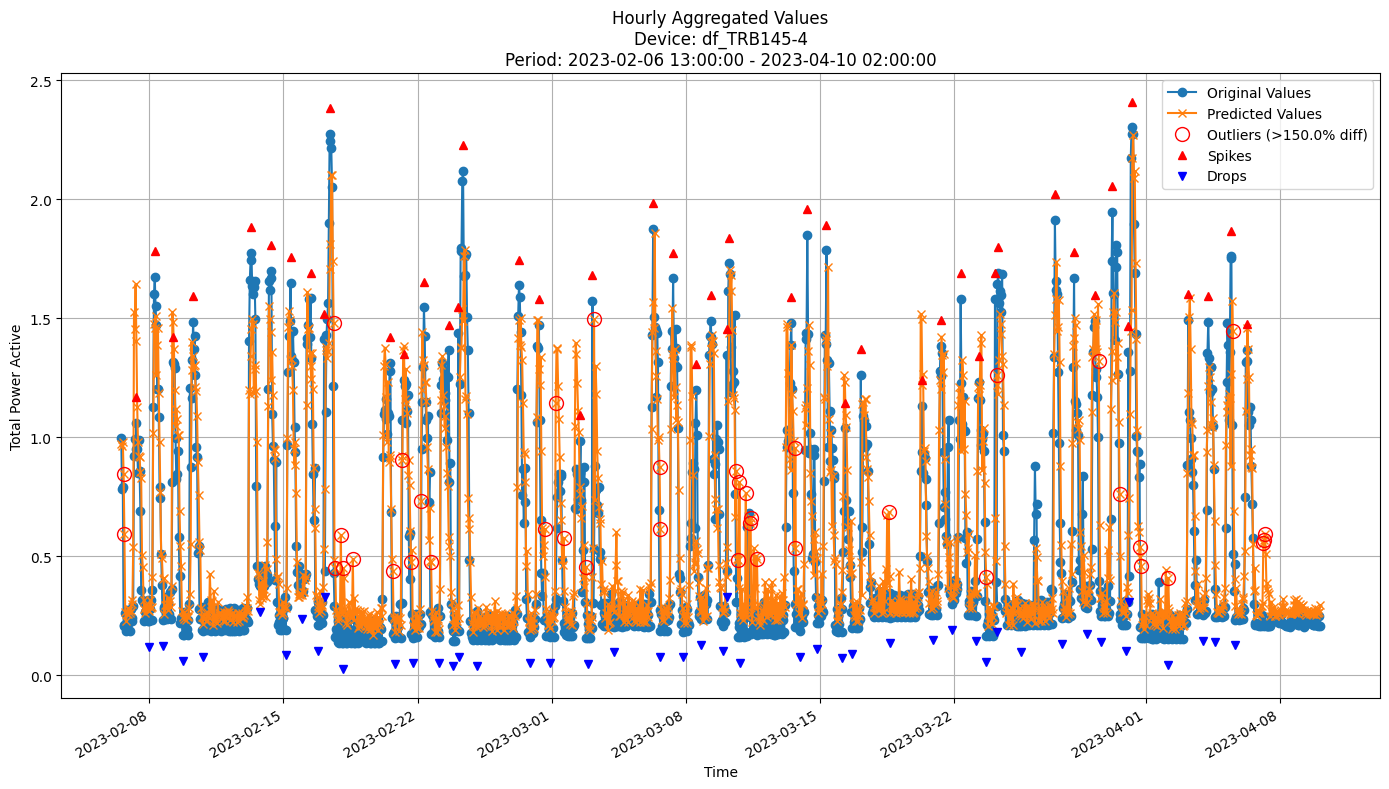


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2195
MAE: 0.1398
MAPE: 33.6987%

Directional Metrics:
Directional Accuracy: 59.5603%
First-Diff Correlation: 0.3785

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0476
  Recall: 0.0426
  F1 Score: 0.0449
Drops:
  Precision: 0.1463
  Recall: 0.1304
  F1 Score: 0.1379

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3571
  Recall: 0.3191
  F1 Score: 0.3371
Drops:
  Precision: 0.1707
  Recall: 0.1522
  F1 Score: 0.1609


In [16]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# 0.22, 0.15, 39.79, 60.39%, 0.39

### Random Forest model

In [17]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=10,
    max_features='sqrt',
    random_state=42, 
    n_jobs=-1)


In [18]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 0.13 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 0.13 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2993
	MAE: 0.1853
	MAPE: 21.3879%

Directional Metrics:
	Directional Accuracy: 60.2086%
	First-Diff Correlation: 0.3247

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.3333
		Recall: 0.0909
		F1: 0.1429


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 0.15 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 0.13 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2835
	MAE: 0.1840
	MAPE: 32.3479%

Directional Metrics:
	Directional Accuracy: 59.3145%
	First-Diff Correlation: 0.4329

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 0.19 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 0.20 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2388
	MAE: 0.1581
	MAPE: 35.5592%

Directional Metrics:
	Directional Accuracy: 52.6080%
	First-Diff Correlation: 0.3214

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0833
		Recall: 0.0526
		F1: 0.0645
	Drops:
		Precision: 0.0833
		Recall: 0.0500
		F1: 0.0625


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 0.23 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1629
	MAE: 0.0982
	MAPE: 26.4494%

Directional Metrics:
	Directional Accuracy: 54.1401%
	First-Diff Correlation: 0.3509

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.6667
		Recall: 0.5000
		F1: 0.5714
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7500
		F1: 0.8571
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------

#### Results

In [19]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1121 ± 0.0109
	MAE: 0.0657 ± 0.0060
	MAPE: 12.0611% ± 1.3292%

	Directional Metrics:
		Directional Accuracy: 78.0257% ± 1.7997%
		First-Diff Correlation: 0.8786 ± 0.0325

	Immediate Detection (delta=0):
		Spike Precision: 0.3766 ± 0.3610
		Spike Recall: 0.1696 ± 0.1838
		Spike F1: 0.2066 ± 0.1960
		Drop Precision: 0.0560 ± 0.0988
		Drop Recall: 0.0516 ± 0.0967
		Drop F1: 0.0535 ± 0.0974

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4531 ± 0.4038
		Spike Recall: 0.2264 ± 0.2608
		Spike F1: 0.2699 ± 0.2759
		Drop Precision: 0.0800 ± 0.1393
		Drop Recall: 0.0734 ± 0.1358
		Drop F1: 0.0762 ± 0.1371
Daily Metrics:
	RMSE: 0.8365 ± 0.0980
	MAE: 0.6152 ± 0.0705
	MAPE: 4.3721% ± 0.3706%

	Directional Metrics:
		Directional Accuracy: 90.6304% ± 3.7904%
		First-Diff Correlation: 0.9949 ± 0.0013

	Immediate Detection (delta=0):


#### Feature importance
[WiP] Right now only for the last split and last device

In [20]:
feat_imps = sorted(
    zip(features[2:], rf.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.13092443502837656)),
 ('L3_act_power_lag_1h', np.float64(0.08706141874839739)),
 ('L1_act_power_lag_1h', np.float64(0.07877863378325366)),
 ('L3_app_power_lag_1h', np.float64(0.06553978046751792)),
 ('powerfactor3_lag_1h', np.float64(0.062356444548132516)),
 ('L2_act_power_lag_1h', np.float64(0.062135635279990574)),
 ('L2_current_lag_1h', np.float64(0.058767404985168616)),
 ('L1_app_power_lag_1h', np.float64(0.05610905975729264)),
 ('L3_current_lag_1h', np.float64(0.051358768289945234)),
 ('hour', np.float64(0.04538617571474976)),
 ('L2_app_power_lag_1h', np.float64(0.044414541617448886)),
 ('L2_react_power_lag_1h', np.float64(0.022629506250714703)),
 ('L2_current_lag_24h', np.float64(0.020464881900435522)),
 ('L1_react_power_lag_1h', np.float64(0.01985525501711811)),
 ('L2_app_power_lag_24h', np.float64(0.016238609827202)),
 ('L2_act_power_lag_24h', np.float64(0.01607517832982089)),
 ('L1_app_power_lag_24h', np.float64(0.014079573901327769)),
 ('L3_

#### Training plots
Plot only the last period of predictions

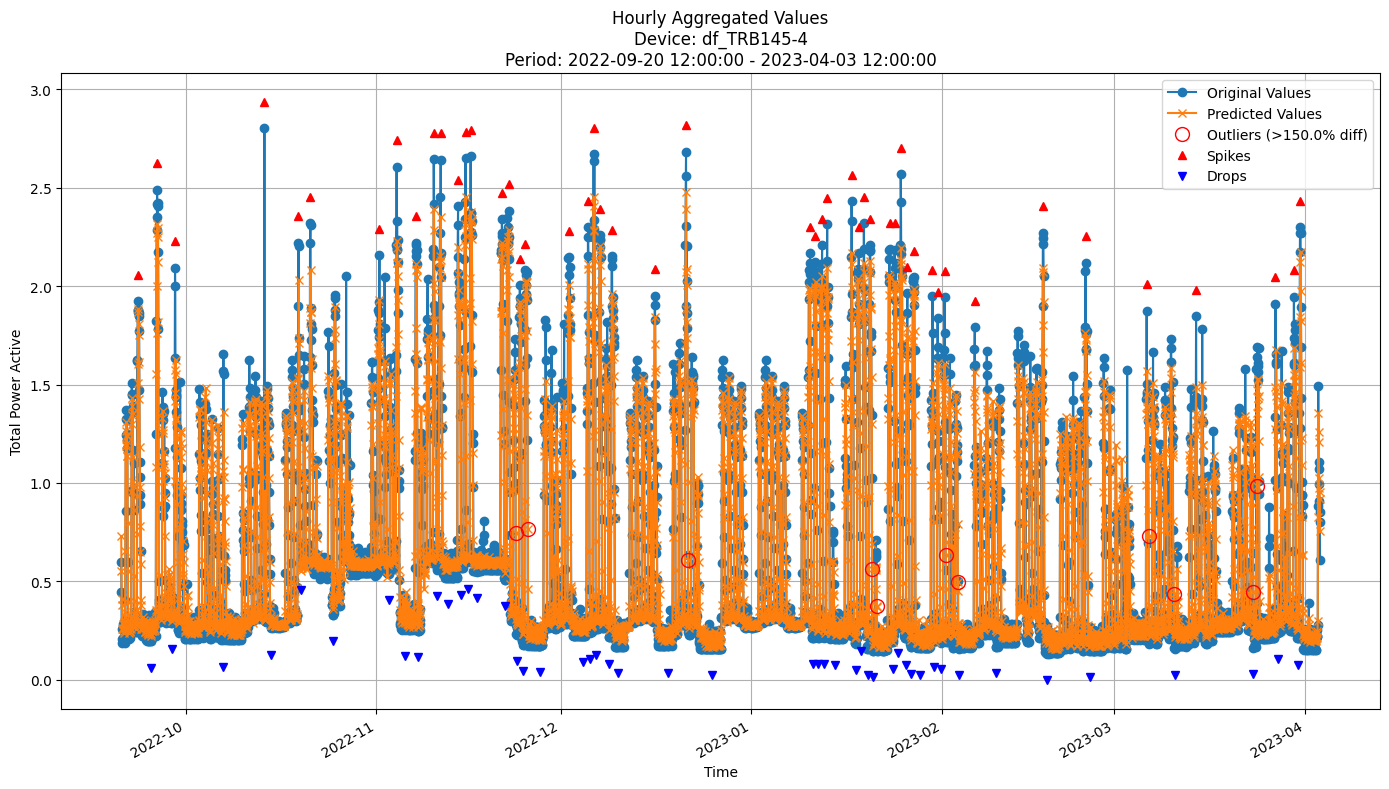


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1286
MAE: 0.0756
MAPE: 14.6978%

Directional Metrics:
Directional Accuracy: 75.1923%
First-Diff Correlation: 0.8301

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5000
  Recall: 0.3673
  F1 Score: 0.4235
Drops:
  Precision: 0.1143
  Recall: 0.0833
  F1 Score: 0.0964

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7778
  Recall: 0.5714
  F1 Score: 0.6588
Drops:
  Precision: 0.1714
  Recall: 0.1250
  F1 Score: 0.1446


In [21]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

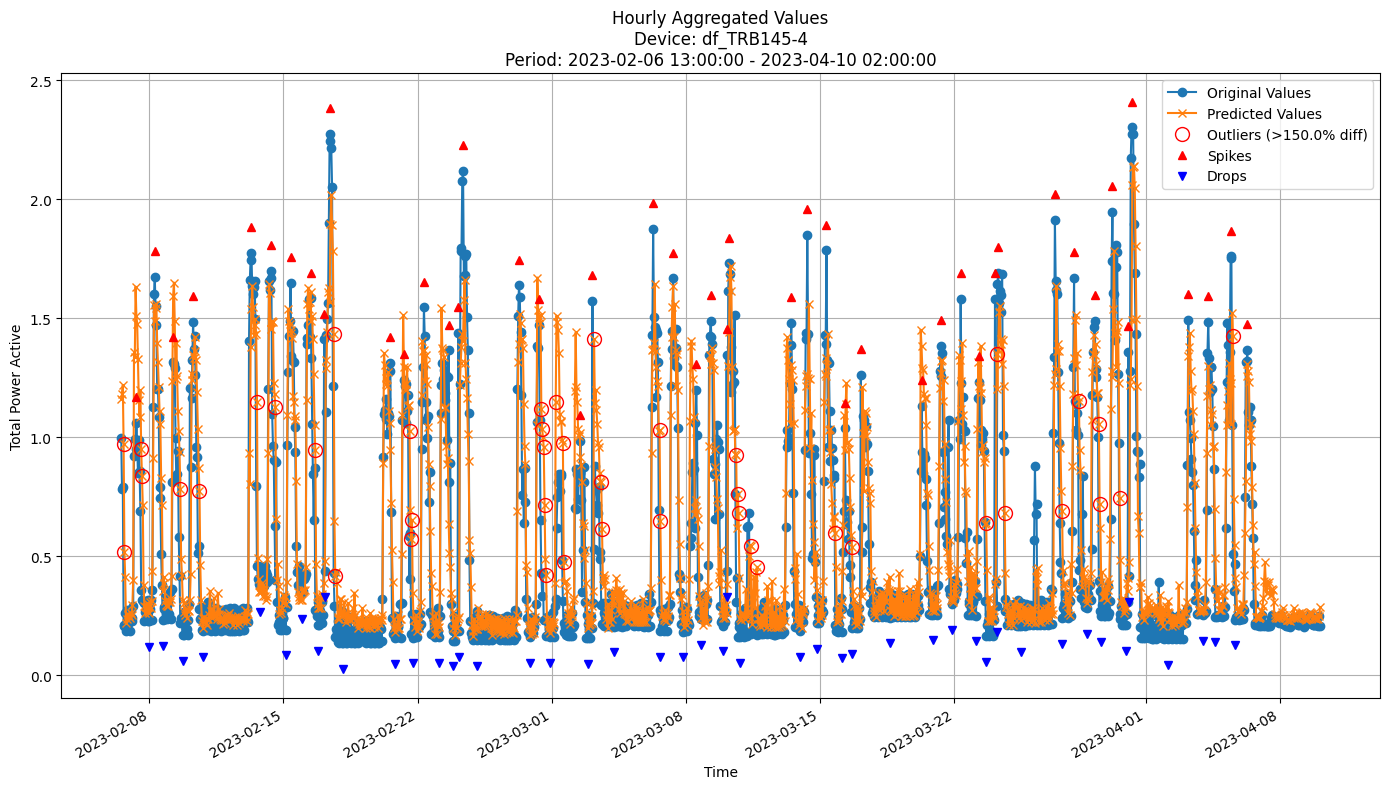


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2347
MAE: 0.1483
MAPE: 34.6715%

Directional Metrics:
Directional Accuracy: 59.0273%
First-Diff Correlation: 0.4102

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0750
  Recall: 0.0638
  F1 Score: 0.0690
Drops:
  Precision: 0.1795
  Recall: 0.1522
  F1 Score: 0.1647

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2750
  Recall: 0.2340
  F1 Score: 0.2529
Drops:
  Precision: 0.2308
  Recall: 0.1957
  F1 Score: 0.2118


In [22]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [23]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

grace_period = 10
delta = 0.5
max_depth = 10
tau = 0.05

hoef = HoeffdingTreeRegressor(
        max_depth=max_depth,
        grace_period=grace_period,
        delta=delta,
        tau=tau,
        leaf_prediction="mean"
    )


In [24]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=hoef, 
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3746
	MAE: 0.2556
	MAPE: 29.1036%

Directional Metrics:
	Directional Accuracy: 45.3055%
	First-Diff Correlation: 0.2171

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.1078
	MAE: 4.0

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3566
	MAE: 0.2247
	MAPE: 33.0720%

Directional Metrics:
	Directional Accuracy: 52.0119%
	First-Diff Correlation: 0.2745

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.8259
	MAE: 3.0

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2995
	MAE: 0.1876
	MAPE: 36.9397%

Directional Metrics:
	Directional Accuracy: 49.4784%
	First-Diff Correlation: 0.2496

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1053
		Recall: 0.1053
		F1: 0.1053
	Drops:
		Precision: 0.0500
		Recall: 0.0500
		F1: 0.0500

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3158
		Recall: 0.3158
		F1: 0.3158
	Drops:
		Precision: 0.2500
		Recall: 0.2500
		F1: 0.2500
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.7277
	MAE: 2.2

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1994
	MAE: 0.1174
	MAPE: 28.7214%

Directional Metrics:
	Directional Accuracy: 57.3248%
	First-Diff Correlation: 0.2887

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.2500
		F1: 0.2500
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2500
		Recall: 0.2500
		F1: 0.2500
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.7537
	MAE: 1.5

#### Results

In [25]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2769 ± 0.0336
	MAE: 0.1652 ± 0.0247
	MAPE: 28.4640% ± 5.7028%

	Directional Metrics:
		Directional Accuracy: 36.6377% ± 6.1702%
		First-Diff Correlation: 0.3328 ± 0.0960

	Immediate Detection (delta=0):
		Spike Precision: 0.0602 ± 0.0696
		Spike Recall: 0.0578 ± 0.0692
		Spike F1: 0.0581 ± 0.0676
		Drop Precision: 0.0362 ± 0.0435
		Drop Recall: 0.0398 ± 0.0463
		Drop F1: 0.0373 ± 0.0436

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1540 ± 0.1789
		Spike Recall: 0.1474 ± 0.1759
		Spike F1: 0.1486 ± 0.1728
		Drop Precision: 0.0512 ± 0.0666
		Drop Recall: 0.0537 ± 0.0640
		Drop F1: 0.0516 ± 0.0639
Daily Metrics:
	RMSE: 2.6302 ± 0.6186
	MAE: 2.0575 ± 0.5088
	MAPE: 14.6692% ± 4.4945%

	Directional Metrics:
		Directional Accuracy: 76.5479% ± 4.1340%
		First-Diff Correlation: 0.9250 ± 0.0506

	Immediate Detection (delta=0):

#### Training plots
Plot only the last period of predictions

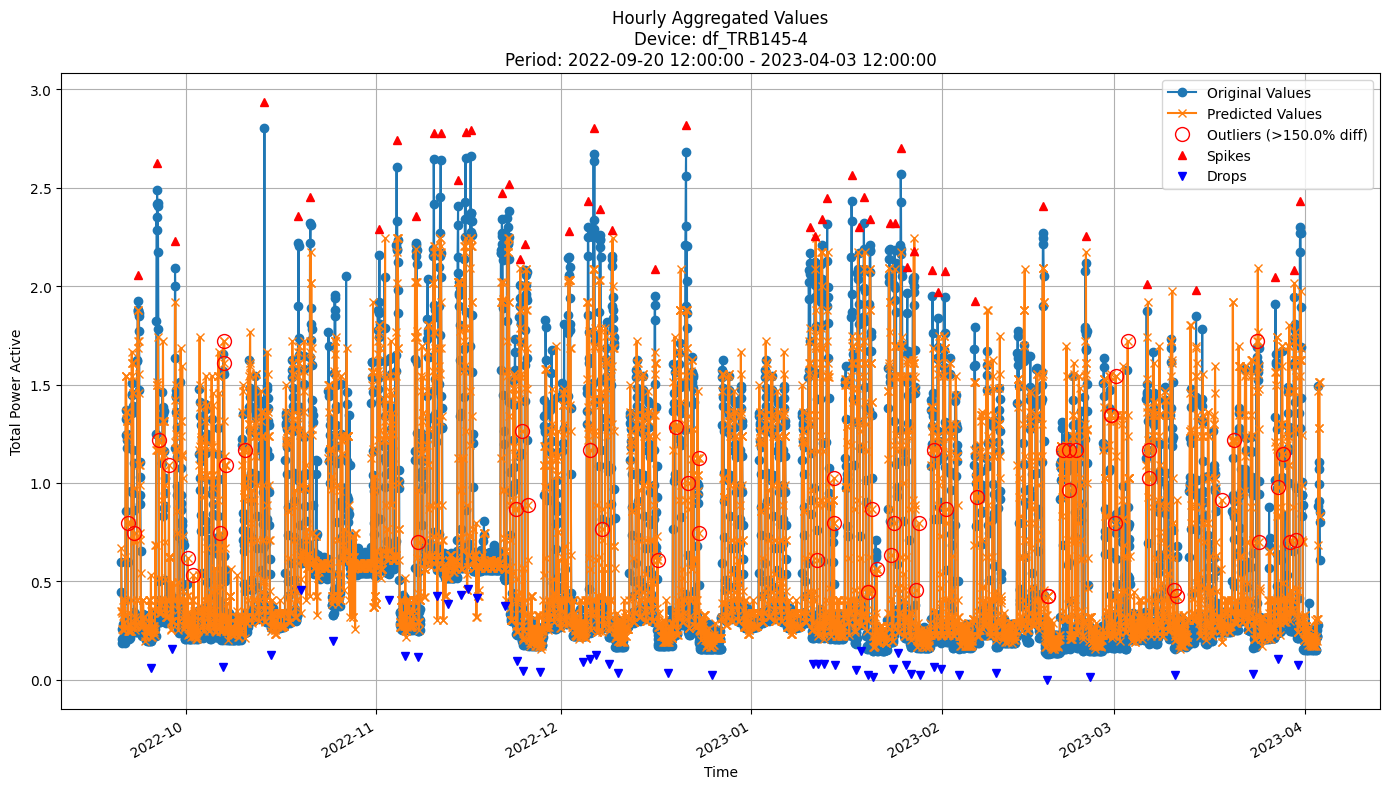


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2446
MAE: 0.1418
MAPE: 25.3569%

Directional Metrics:
Directional Accuracy: 43.6538%
First-Diff Correlation: 0.4135

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1500
  Recall: 0.1224
  F1 Score: 0.1348
Drops:
  Precision: 0.0909
  Recall: 0.1042
  F1 Score: 0.0971

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4000
  Recall: 0.3265
  F1 Score: 0.3596
Drops:
  Precision: 0.1273
  Recall: 0.1458
  F1 Score: 0.1359


In [26]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

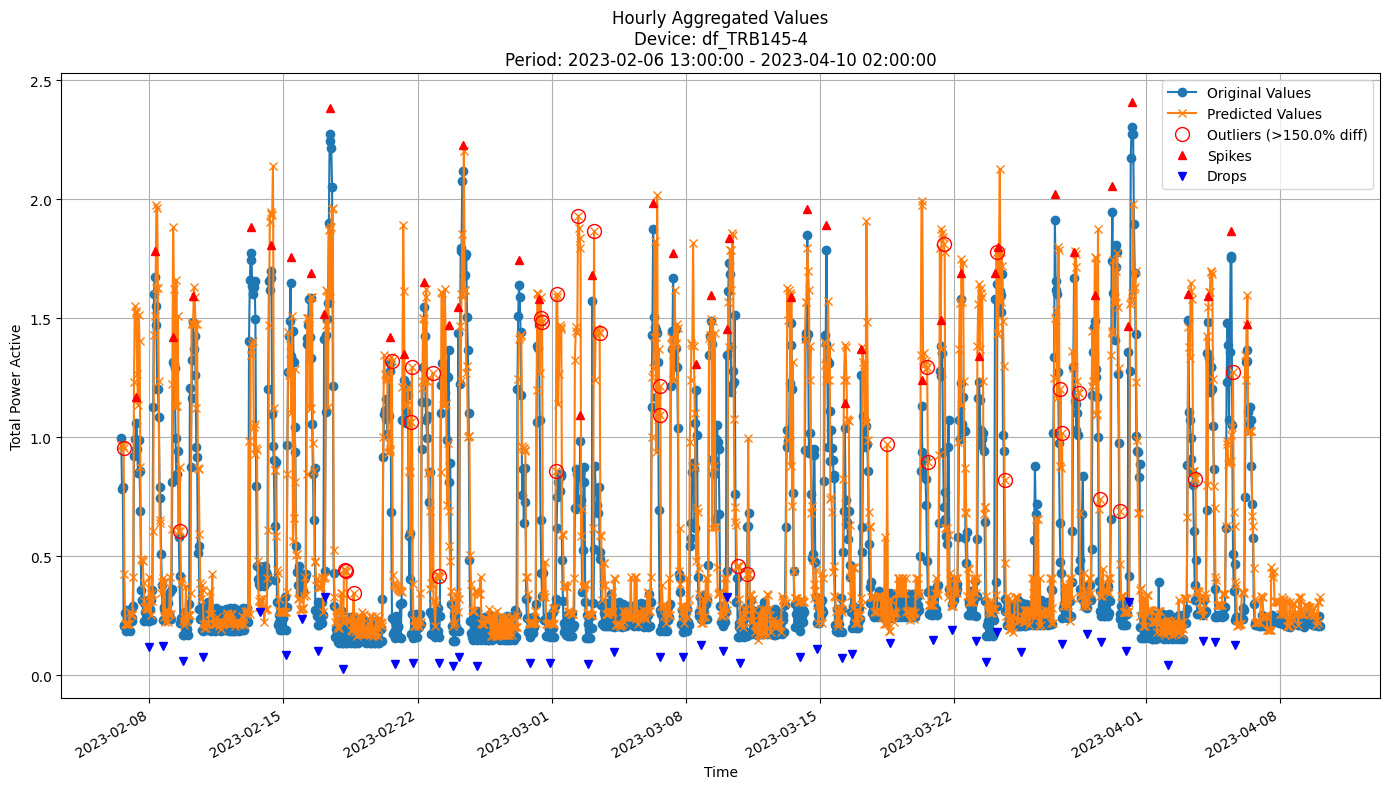


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2891
MAE: 0.1766
MAPE: 37.6427%

Directional Metrics:
Directional Accuracy: 52.2318%
First-Diff Correlation: 0.2959

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1707
  Recall: 0.1489
  F1 Score: 0.1591
Drops:
  Precision: 0.0500
  Recall: 0.0435
  F1 Score: 0.0465

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3415
  Recall: 0.2979
  F1 Score: 0.3182
Drops:
  Precision: 0.2500
  Recall: 0.2174
  F1 Score: 0.2326


In [27]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [28]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
max_features = 0.8
grace_period = 10
split_confidence = 0.5
depth = 10
tau = 0.01

arf_hf = ARFRegressor(
        n_models=n_models,
        max_features=max_features,
        aggregation_method='median',
        grace_period=grace_period,
        max_depth=depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

In [29]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=arf_hf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3631
	MAE: 0.2355
	MAPE: 27.3743%

Directional Metrics:
	Directional Accuracy: 52.1610%
	First-Diff Correlation: 0.3317

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.4454
	MAE: 4.2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3245
	MAE: 0.2214
	MAPE: 39.9123%

Directional Metrics:
	Directional Accuracy: 57.9732%
	First-Diff Correlation: 0.4104

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.9443
	MAE: 3.1

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2498
	MAE: 0.1676
	MAPE: 37.3576%

Directional Metrics:
	Directional Accuracy: 51.8629%
	First-Diff Correlation: 0.3531

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1053
		Recall: 0.1000
		F1: 0.1026

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3158
		Recall: 0.3158
		F1: 0.3158
	Drops:
		Precision: 0.1579
		Recall: 0.1500
		F1: 0.1538
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.3846
	MAE: 1.9

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1904
	MAE: 0.1279
	MAPE: 40.8609%

Directional Metrics:
	Directional Accuracy: 59.2357%
	First-Diff Correlation: 0.4171

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3333
		Recall: 0.2500
		F1: 0.2857
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.2832
	MAE: 1.8

#### Results

In [30]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2586 ± 0.0565
	MAE: 0.1637 ± 0.0445
	MAPE: 31.6056% ± 11.1158%

	Directional Metrics:
		Directional Accuracy: 58.5306% ± 7.2030%
		First-Diff Correlation: 0.4946 ± 0.1244

	Immediate Detection (delta=0):
		Spike Precision: 0.1061 ± 0.1370
		Spike Recall: 0.0573 ± 0.0757
		Spike F1: 0.0737 ± 0.0958
		Drop Precision: 0.0501 ± 0.0579
		Drop Recall: 0.0278 ± 0.0332
		Drop F1: 0.0353 ± 0.0413

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1996 ± 0.2542
		Spike Recall: 0.1079 ± 0.1412
		Spike F1: 0.1387 ± 0.1784
		Drop Precision: 0.0631 ± 0.0757
		Drop Recall: 0.0347 ± 0.0422
		Drop F1: 0.0443 ± 0.0529
Daily Metrics:
	RMSE: 3.1903 ± 0.9528
	MAE: 2.4899 ± 0.8054
	MAPE: 20.5581% ± 9.5556%

	Directional Metrics:
		Directional Accuracy: 76.8486% ± 5.8319%
		First-Diff Correlation: 0.8792 ± 0.1838

	Immediate Detection (delta=0)

#### Training plots

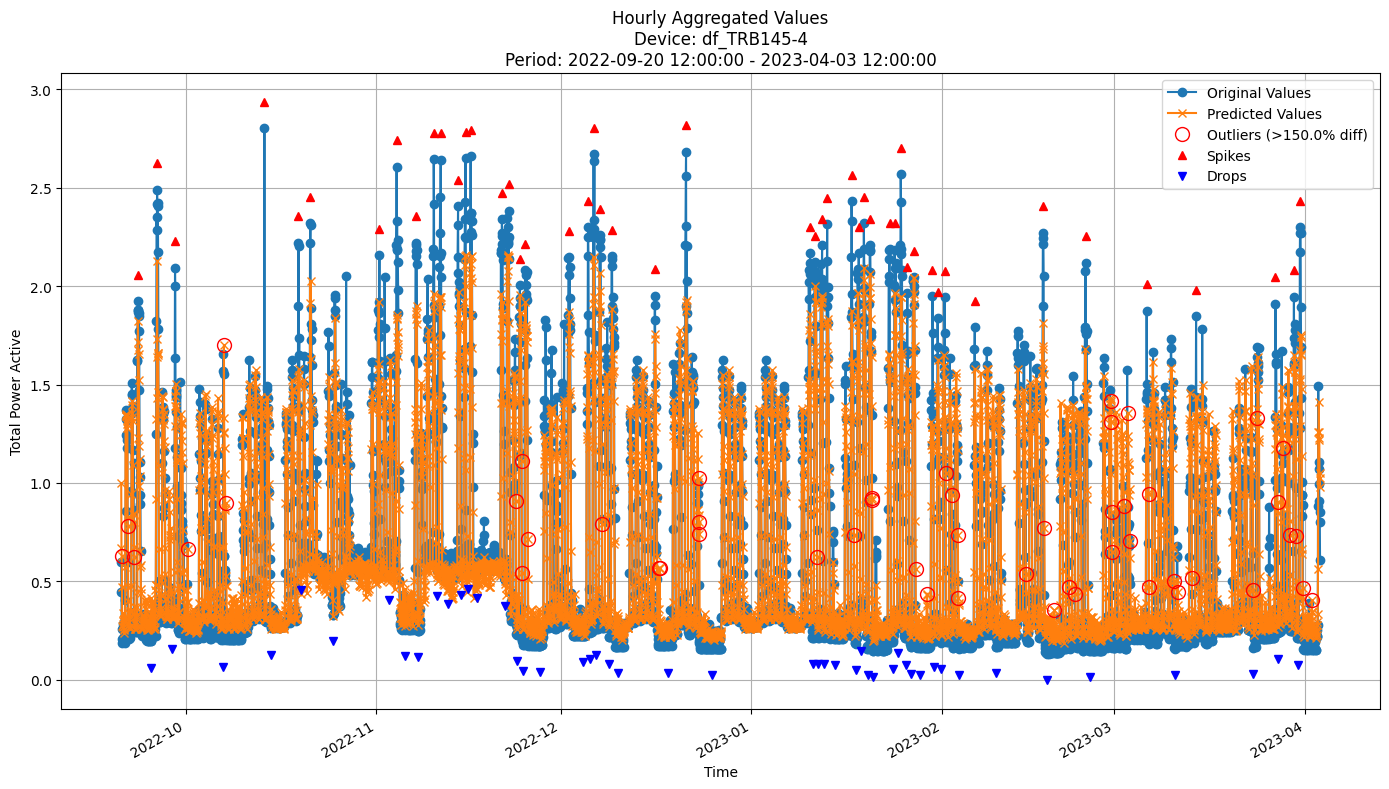


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2175
MAE: 0.1308
MAPE: 25.1906%

Directional Metrics:
Directional Accuracy: 62.5641%
First-Diff Correlation: 0.5781

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2647
  Recall: 0.1837
  F1 Score: 0.2169
Drops:
  Precision: 0.1143
  Recall: 0.0833
  F1 Score: 0.0964

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.3469
  F1 Score: 0.4096
Drops:
  Precision: 0.1429
  Recall: 0.1042
  F1 Score: 0.1205


In [31]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

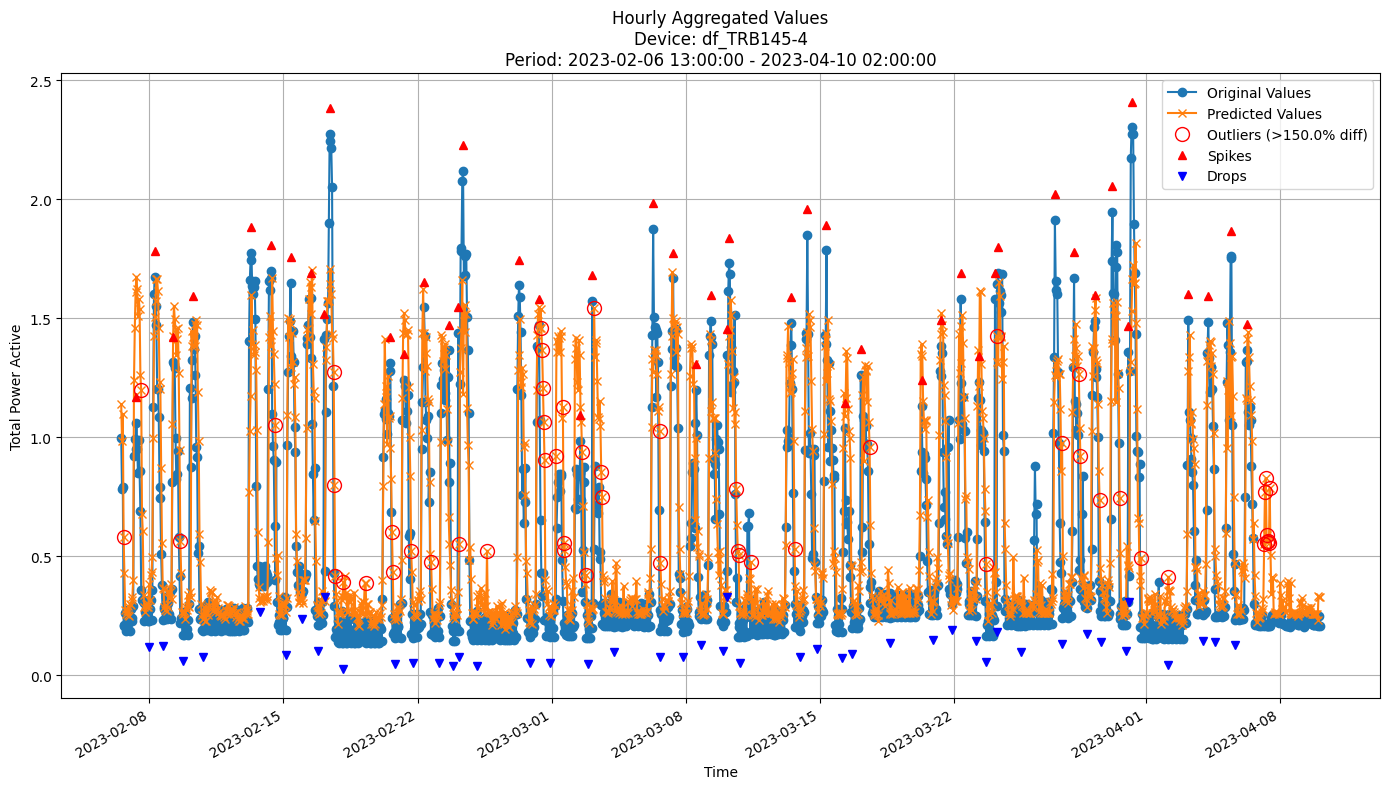


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2560
MAE: 0.1695
MAPE: 41.2028%

Directional Metrics:
Directional Accuracy: 58.0280%
First-Diff Correlation: 0.4114

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1163
  Recall: 0.1064
  F1 Score: 0.1111
Drops:
  Precision: 0.0930
  Recall: 0.0870
  F1 Score: 0.0899

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4186
  Recall: 0.3830
  F1 Score: 0.4000
Drops:
  Precision: 0.1395
  Recall: 0.1304
  F1 Score: 0.1348


In [32]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [33]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.001
depth = 100
eagerness = 100
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
fodt = fastodt.FastODT(
        depth=depth,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf',
        eagerness = eagerness,
        grace_period_depth = -1
    )

In [34]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5252
	MAE: 0.3726
	MAPE: 42.1575%

Directional Metrics:
	Directional Accuracy: 45.0075%
	First-Diff Correlation: 0.0603

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 8.5282
	MAE: 7.0

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5861
	MAE: 0.4489
	MAPE: 84.5777%

Directional Metrics:
	Directional Accuracy: 47.9881%
	First-Diff Correlation: 0.1647

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 8.9469
	MAE: 7.5

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3942
	MAE: 0.3001
	MAPE: 92.8404%

Directional Metrics:
	Directional Accuracy: 51.4158%
	First-Diff Correlation: 0.1389

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.0348
	MAE: 4.5

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4177
	MAE: 0.3180
	MAPE: 124.4454%

Directional Metrics:
	Directional Accuracy: 56.0510%
	First-Diff Correlation: 0.2267

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.8031
	MAE: 4.

#### Results

In [35]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4687 ± 0.0237
	MAE: 0.3495 ± 0.0232
	MAPE: 77.4546% ± 8.0855%

	Directional Metrics:
		Directional Accuracy: 19.4210% ± 4.0944%
		First-Diff Correlation: 0.1418 ± 0.0732

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 7.3219 ± 0.6352
	MAE: 6.0071 ± 0.4922
	MAPE: 58.2221% ± 6.0527%

	Directional Metrics:
		Directional Accuracy: 1.3512% ± 1.0450%
		First-Diff Correlation: 0.0881 ± 0.0400

	Immediate Detection (delta=0):


#### Training plots


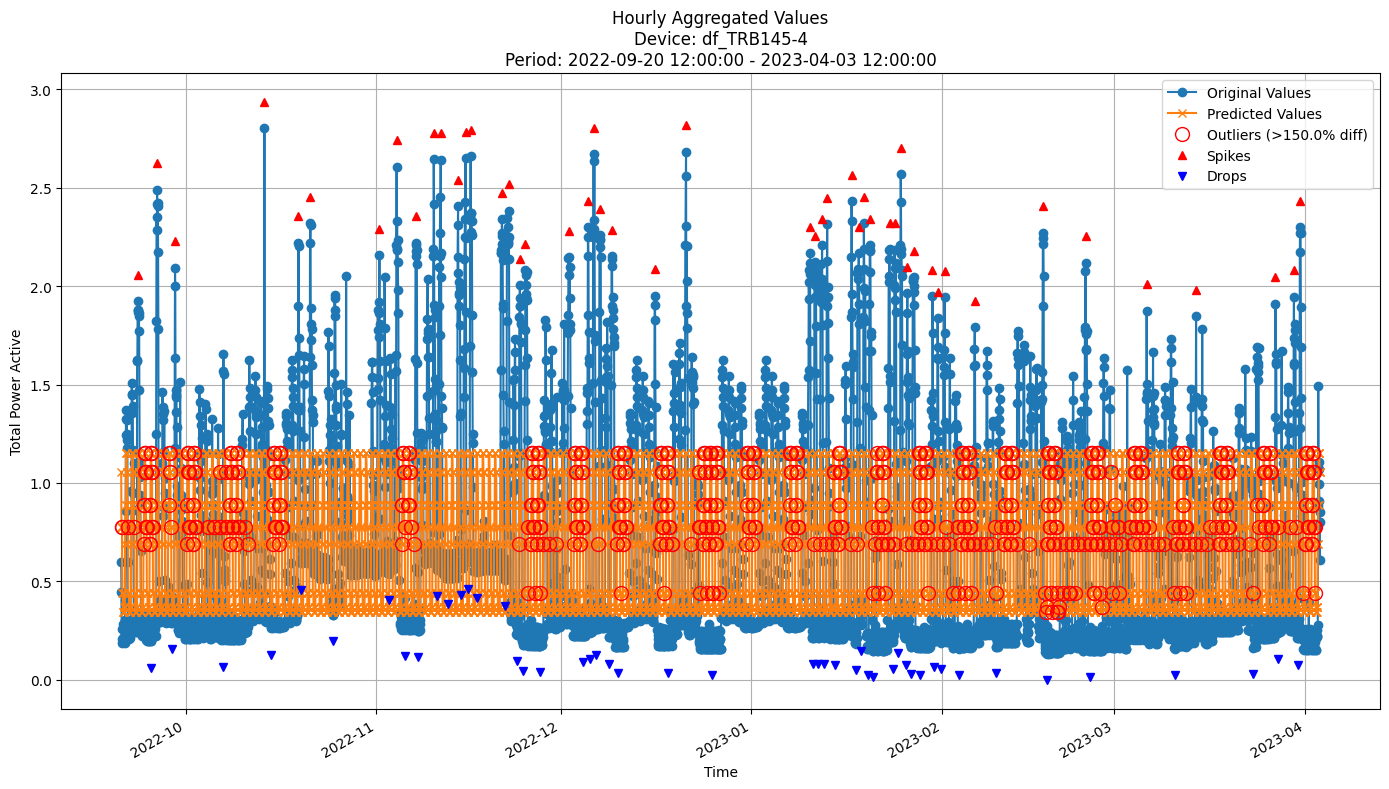


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4601
MAE: 0.3409
MAPE: 85.4309%

Directional Metrics:
Directional Accuracy: 23.0556%
First-Diff Correlation: 0.2543

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [36]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

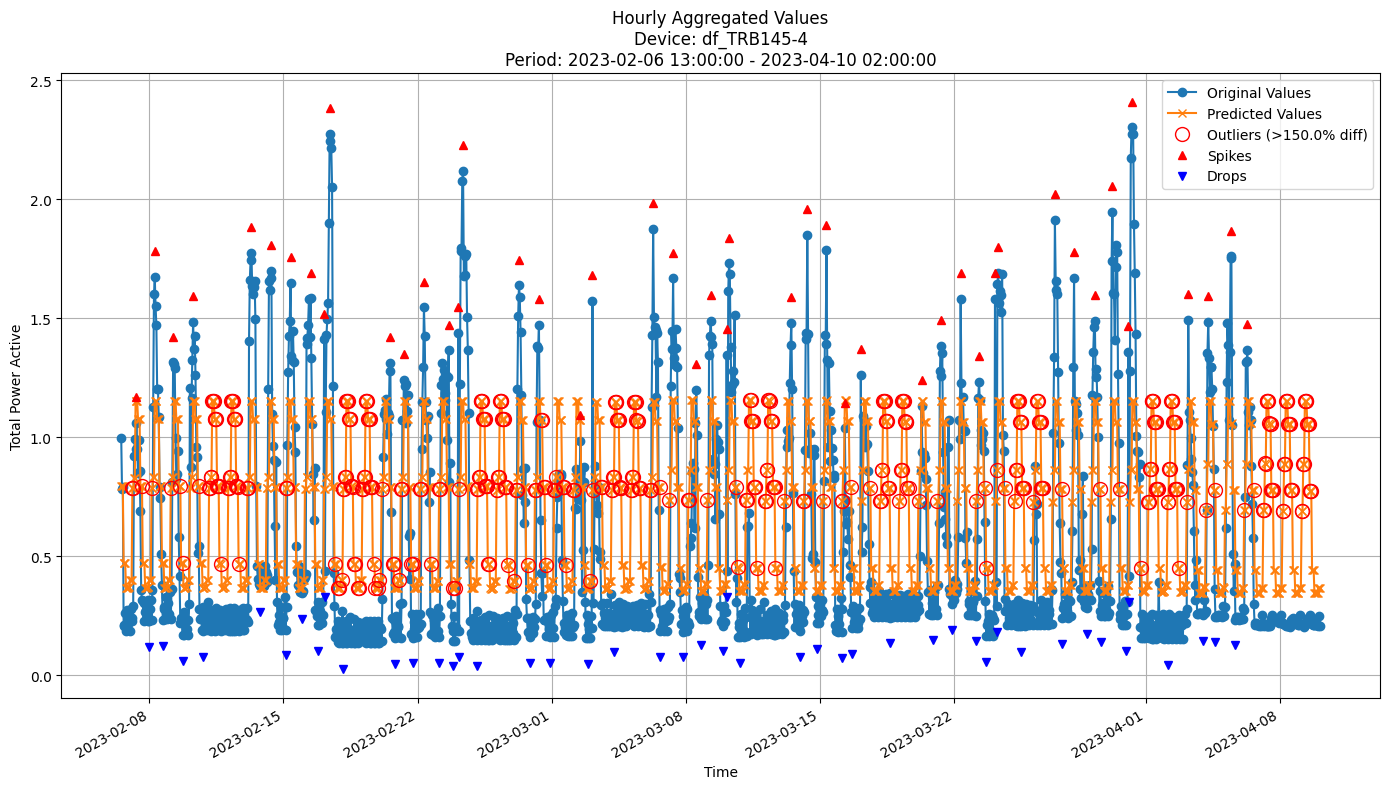


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4086
MAE: 0.3167
MAPE: 108.9418%

Directional Metrics:
Directional Accuracy: 52.9647%
First-Diff Correlation: 0.1965

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [37]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [38]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 20
grace_period = 0  # by default works for all leaves
aggregation_method = "mean"
split_confidence = 0.005
tau = 0.01
max_depth = 100
eagerness = 200

arf = ARFRegressorFODT(
        n_models=n_models,
        aggregation_method=aggregation_method,
        grace_period=grace_period,
        max_depth=max_depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
        max_feature=0.7,
        eagerness=eagerness,
    )


In [39]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=arf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5096
	MAE: 0.3400
	MAPE: 38.0936%

Directional Metrics:
	Directional Accuracy: 55.2906%
	First-Diff Correlation: 0.2761

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.0909
		F1: 0.1333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2500
		Recall: 0.0909
		F1: 0.1333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.7069
	MAE: 6.4

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5448
	MAE: 0.4240
	MAPE: 84.9800%

Directional Metrics:
	Directional Accuracy: 57.5261%
	First-Diff Correlation: 0.4735

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.4049
	MAE: 6.0

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2992
	MAE: 0.2271
	MAPE: 61.3363%

Directional Metrics:
	Directional Accuracy: 56.7809%
	First-Diff Correlation: 0.3687

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.7786
	MAE: 3.0

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2741
	MAE: 0.2427
	MAPE: 85.4338%

Directional Metrics:
	Directional Accuracy: 54.1401%
	First-Diff Correlation: 0.5841

Immediate Detection (delta=0):
	Spikes:
		Precision: 1.0000
		Recall: 0.2500
		F1: 0.4000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.2500
		F1: 0.4000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.9576
	MAE: 3.0

#### Results

In [40]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4065 ± 0.0321
	MAE: 0.3001 ± 0.0376
	MAPE: 64.6975% ± 11.4999%

	Directional Metrics:
		Directional Accuracy: 61.5790% ± 0.7798%
		First-Diff Correlation: 0.4273 ± 0.0601

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 6.1132 ± 0.6401
	MAE: 4.9349 ± 0.6202
	MAPE: 44.8681% ± 6.3616%

	Directional Metrics:
		Directional Accuracy: 69.5207% ± 5.9055%
		First-Diff Correlation: 0.7699 ± 0.0781

	Immediate Detection (delta=0)

#### Training plots


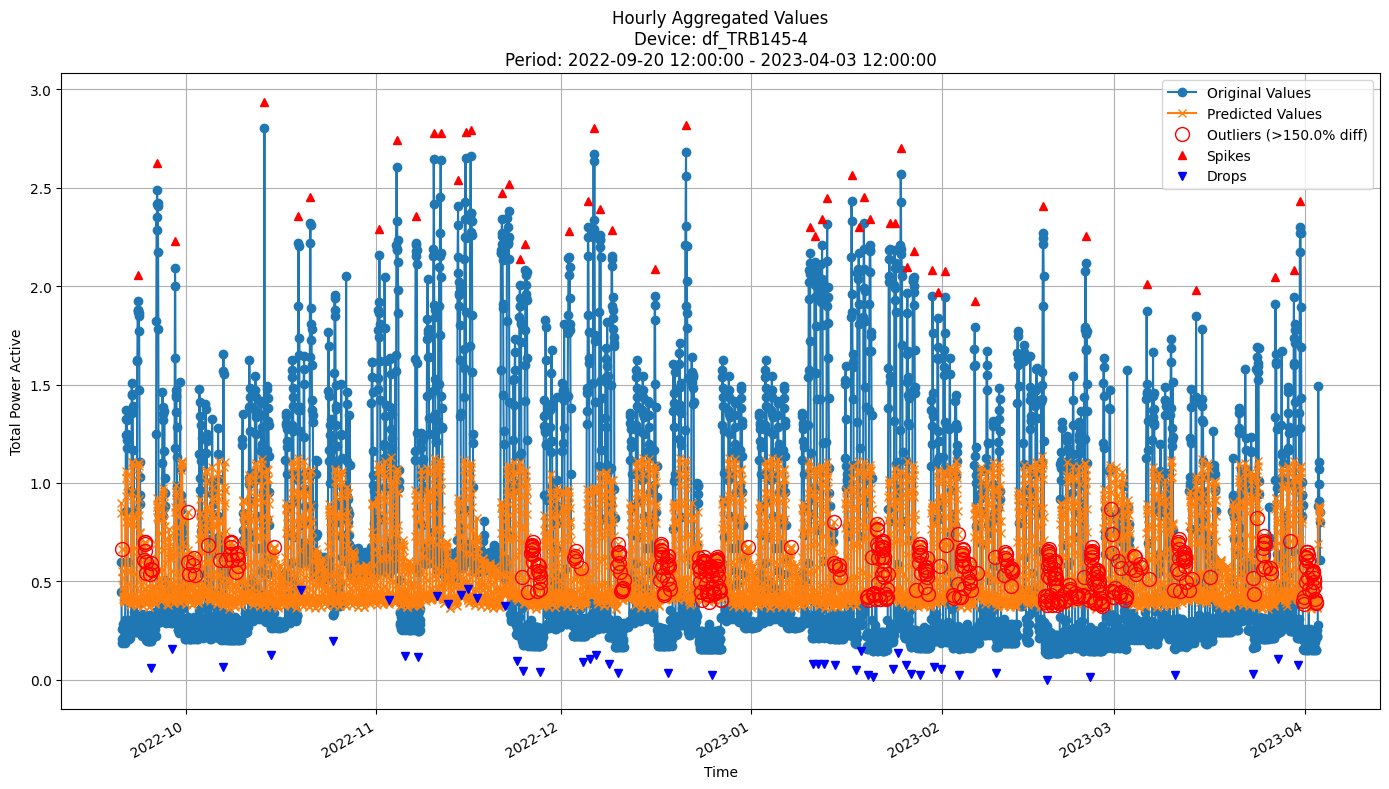


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4180
MAE: 0.3041
MAPE: 64.5435%

Directional Metrics:
Directional Accuracy: 60.5556%
First-Diff Correlation: 0.4762

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [41]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

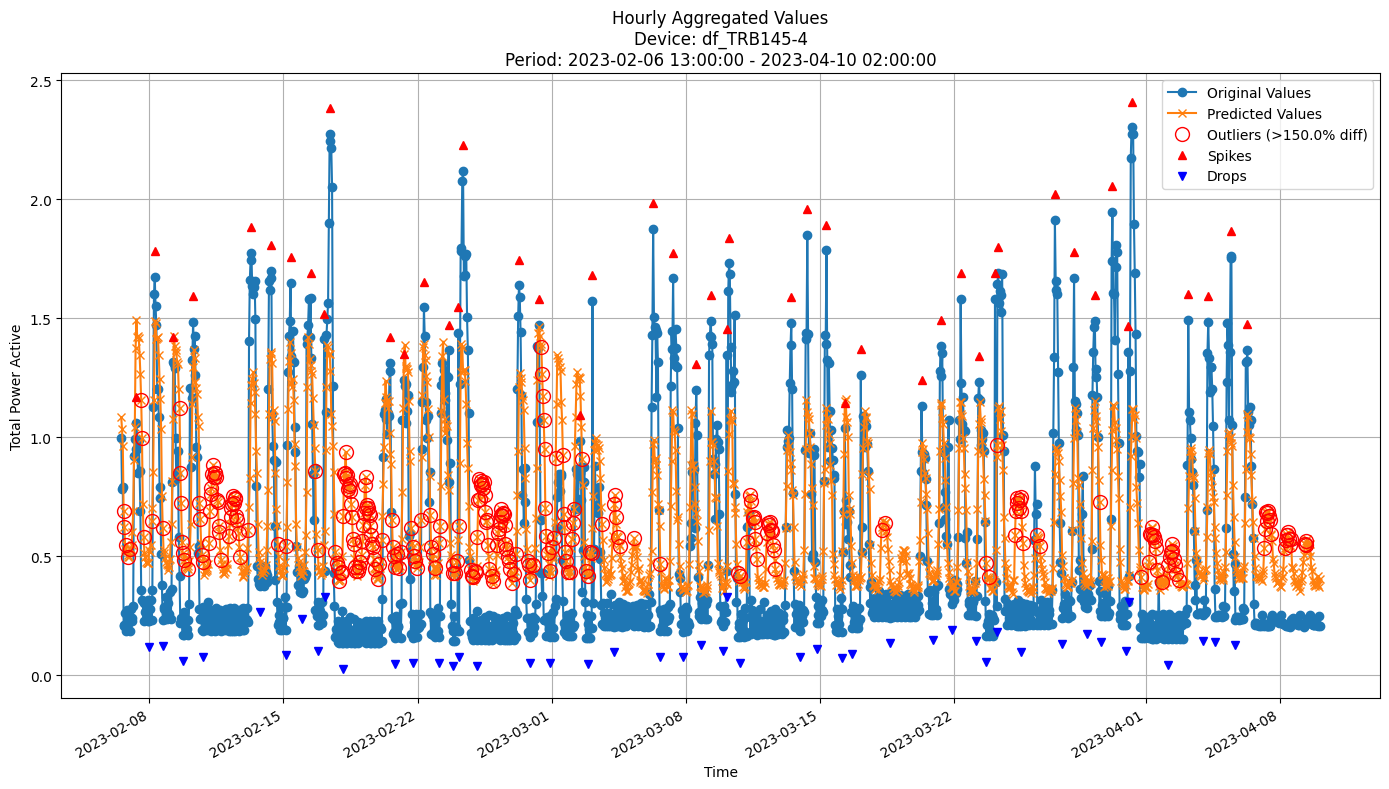


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3263
MAE: 0.2672
MAPE: 86.6978%

Directional Metrics:
Directional Accuracy: 56.0293%
First-Diff Correlation: 0.4060

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [42]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [43]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:
split_confidence_hf = 0.001
n_trees = 10
depth = 100
grace_period = 10
max_feature = 1.0
eagerness = 1000
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
incb = IncubationBoost(
    fastodt.FastODT,
    length=n_trees,
    incubationMode = "DEFAULT",
    baseLearnerOptions = (depth, grace_period, split_confidence, "hf", max_features, eagerness, grace_period_depth),
    verbose=False
    )


In [44]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5009
	MAE: 0.3514
	MAPE: 40.3078%

Directional Metrics:
	Directional Accuracy: 43.8152%
	First-Diff Correlation: 0.2990

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 8.2563
	MAE: 6.8

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5706
	MAE: 0.4375
	MAPE: 86.2903%

Directional Metrics:
	Directional Accuracy: 47.8390%
	First-Diff Correlation: 0.3608

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 8.8234
	MAE: 7.4

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3942
	MAE: 0.2994
	MAPE: 95.2304%

Directional Metrics:
	Directional Accuracy: 47.5410%
	First-Diff Correlation: 0.3660

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.3915
	MAE: 4.8

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4330
	MAE: 0.3240
	MAPE: 130.9795%

Directional Metrics:
	Directional Accuracy: 51.5924%
	First-Diff Correlation: 0.3288

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.2323
	MAE: 5.

#### Results

In [45]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4607 ± 0.0230
	MAE: 0.3427 ± 0.0207
	MAPE: 79.5611% ± 8.0713%

	Directional Metrics:
		Directional Accuracy: 20.4930% ± 3.0105%
		First-Diff Correlation: 0.2843 ± 0.0770

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 7.3440 ± 0.6323
	MAE: 5.9784 ± 0.4675
	MAPE: 60.4847% ± 5.9651%

	Directional Metrics:
		Directional Accuracy: 1.3512% ± 1.0450%
		First-Diff Correlation: 0.0859 ± 0.0353

	Immediate Detection (delta=0):


#### Train plots

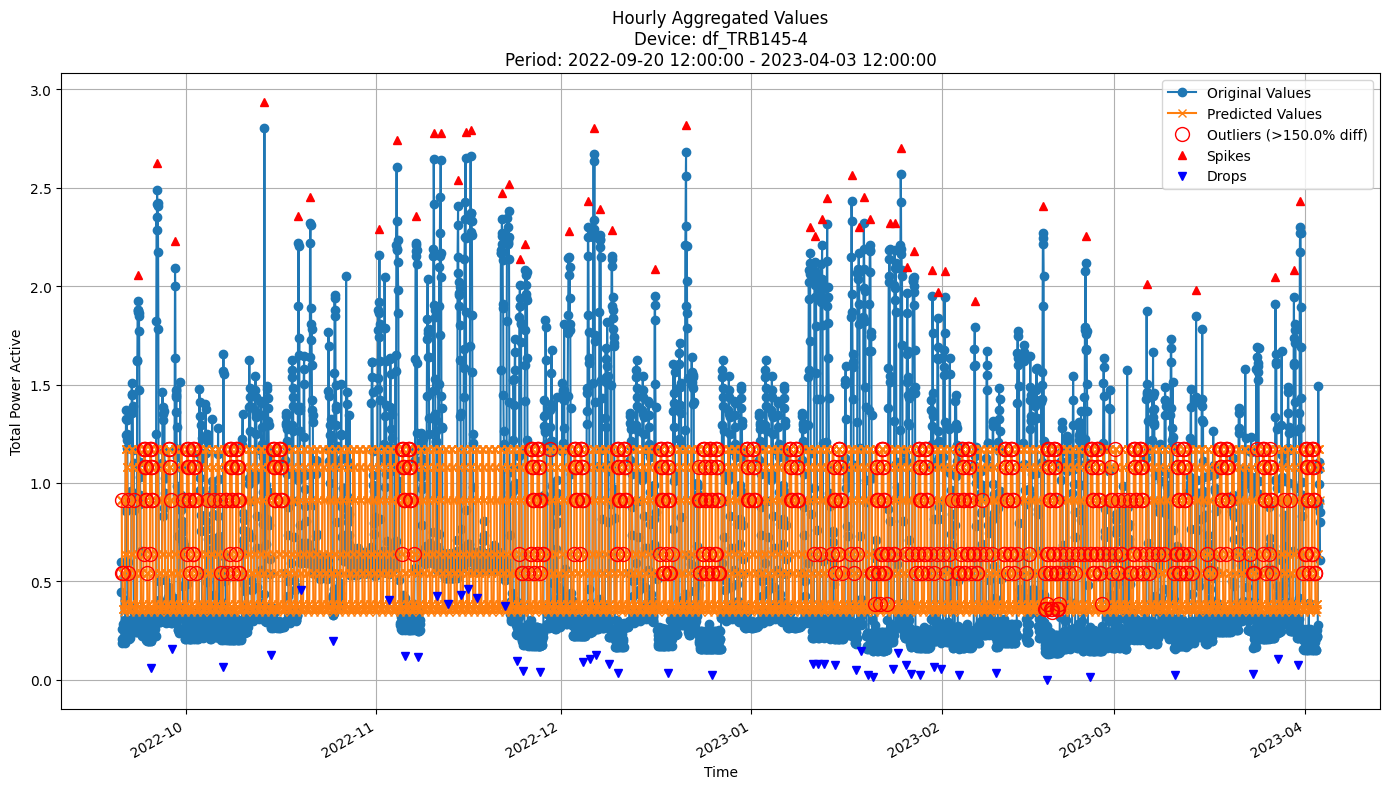


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4588
MAE: 0.3390
MAPE: 88.2414%

Directional Metrics:
Directional Accuracy: 24.4658%
First-Diff Correlation: 0.3493

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [46]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

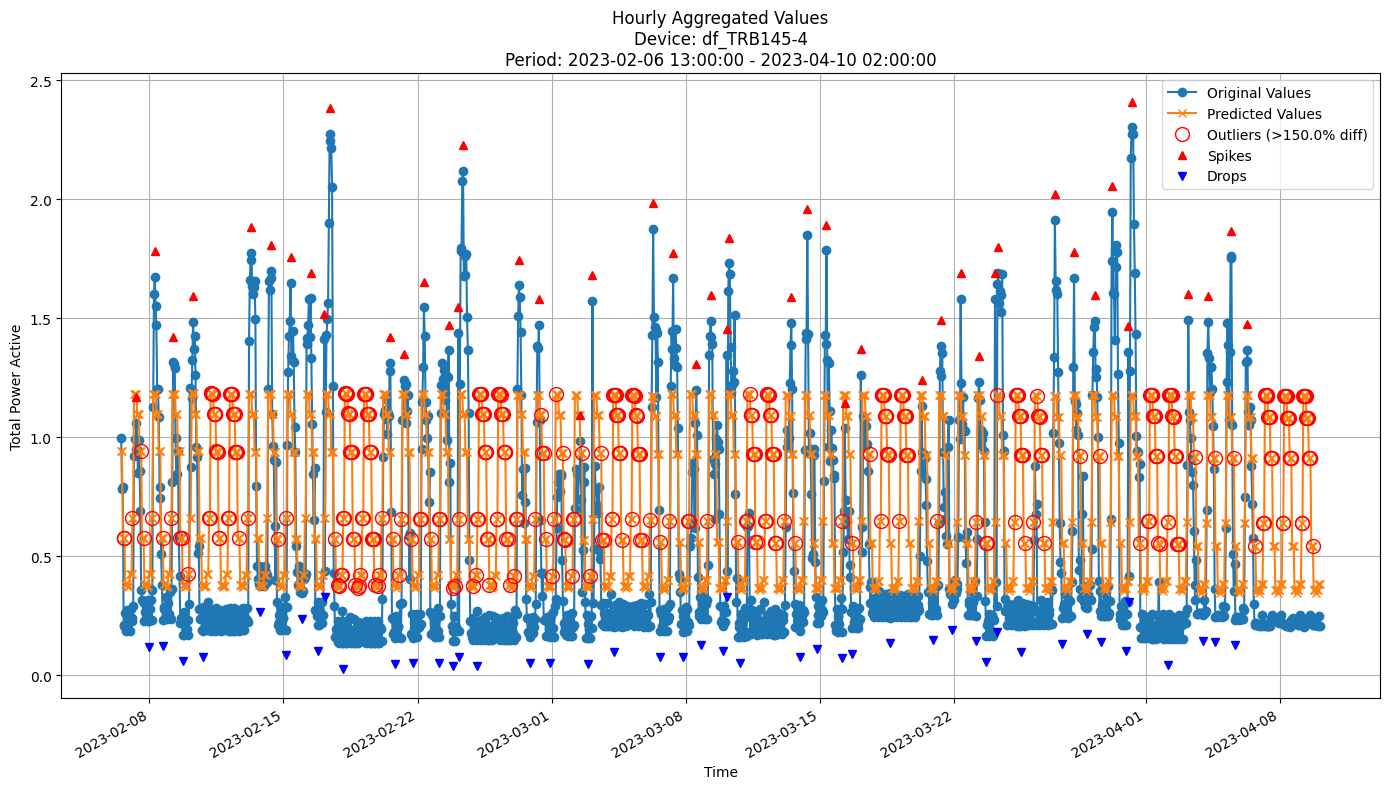


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4129
MAE: 0.3175
MAPE: 112.2868%

Directional Metrics:
Directional Accuracy: 47.3018%
First-Diff Correlation: 0.3655

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [47]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [48]:
last_valid_dates = valid[-1][0][valid[-1][0][:, 1] == "df_TRB145-4"][:, 0]
test_dates = test[0][test[0][:, 1] == "df_TRB145-4"][:, 0]
print(f"Last validation set range: {last_valid_dates[0]} - {last_valid_dates[-1]}")
print(f"Test range: {test_dates[0]} - {test_dates[-1]}")
print(f"Test set length: {len(test_dates)}")

Last validation set range: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
Test range: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
Test set length: 1215


In [59]:
# Initialize the models beforehand to run this cell
models = [baseline, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
model_test_results = {}
for model in models:
    if model in [gbdt, rf]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"Model: {model.__class__.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "1h"
        print(f"Model: {model.__class__.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model=model, 
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        update_freq=update_freq,
        spike_prominence=1.,
        normalize_robust=False,
        predict_train=False,
        verbose=True
    )
    model_test_results[model.__class__.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2078
	MAE: 0.0964
	MAPE: 16.4499%

Directional Metrics:
	Directional Accuracy: 48.8468%
	First-Diff Correlation: 0.1843

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0312
	MAE: 0.0225
	MAPE: 0.1695%

Direction

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00

Time: 11.11 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-04-10 04:00:00 to 2023-04-24 04:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-04-24 04:00:00

Time: 11.95 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-04-24 05:00:00 to 2023-05-08 05:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-05-08 05:00:00

Time: 12.73 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-05-08 06:00:00 to 2023-05-22 06:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-05-22 06:00:00

Time: 13.86 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-05-22 07:00:00 to 2023-05-30 18:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3181
	MAE: 0.2232
	MAPE: 55.1108%

Directional Metrics:
	Directional Accuracy: 61.4498%
	First-Diff Correlation: 0.5012

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1081
		Recall: 0.0909
		F1: 0.0988
	Drops:
		Precision: 0.0833
		Recall: 0.0698
		F1: 0.0759

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6216
		Recall: 0.5227
		F1: 0.5679
	Drops:
		Precision: 0.3333
		Recall: 0.2791
		F1: 0.3038
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.2273
	MAE: 3.2222
	MAPE: 34.8358%

Directio

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4226
	MAE: 0.3063
	MAPE: 96.2193%

Directional Metrics:
	Directional Accuracy: 48.3526%
	First-Diff Correlation: 0.2930

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0980
		Recall: 0.1136
		F1: 0.1053
	Drops:
		Precision: 0.0400
		Recall: 0.0465
		F1: 0.0430

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3725
		Recall: 0.4318
		F1: 0.4000
	Drops:
		Precision: 0.1800
		Recall: 0.2093
		F1: 0.1935
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.9225
	MAE: 5.7457
	MAPE: 75.7515%

Directio

In [60]:
for model in models:
    model_test_results[model.__class__.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__class__.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [51]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [61]:
MODEL_TEST_METRICS = {
    "Baseline": model_test_results[baseline.__class__.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__class__.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__class__.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__class__.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__class__.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__class__.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__class__.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__class__.__name__]["test_metrics"],
}

In [62]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f}"# ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_TEST_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                     "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)",
                                     "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)

    # RandomForest	0.223	0.129	26.880	57.166	40.782	10.127	48.101	2.597	15.584


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.208,0.096,16.450,48.847,18.428,0.000,100.000,0.000,100.000
1,GBDT,0.210,0.125,26.231,54.613,43.860,15.190,48.101,5.195,10.390
2,RandomForest,0.223,0.129,26.880,57.166,40.782,10.127,45.570,2.597,15.584
3,HoeffdingTree,0.268,0.152,29.541,49.753,36.151,9.639,31.325,0.000,12.346
4,ARF_Hoeffding,0.246,0.146,29.381,57.166,39.558,7.595,40.506,10.390,28.571
5,FastODT,0.416,0.301,91.805,52.636,21.120,4.211,33.684,10.753,25.806
6,ARF_FastODT,0.318,0.223,55.111,61.450,50.121,9.877,56.790,7.595,30.380
7,IncubationBoost,0.423,0.306,96.219,48.353,29.299,10.526,40.000,4.301,19.355


## Validation results

In [54]:
MODEL_VALID_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_VALID_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                     "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.228 ± 0.041,0.129 ± 0.030,23.957 ± 7.384,39.392 ± 4.644,18.383 ± 19.704,0.000 ± 0.000,85.714 ± 34.993,0.000 ± 0.000,83.287 ± 34.343
1,GBDT,0.249 ± 0.061,0.159 ± 0.052,33.496 ± 5.359,62.475 ± 7.104,38.209 ± 9.705,12.160 ± 13.546,36.036 ± 29.217,11.018 ± 10.564,13.970 ± 13.616
2,RandomForest,0.112 ± 0.011,0.066 ± 0.006,12.061 ± 1.329,78.026 ± 1.800,87.855 ± 3.247,20.657 ± 19.604,26.994 ± 27.588,5.345 ± 9.743,7.621 ± 13.705
3,HoeffdingTree,0.293 ± 0.057,0.185 ± 0.043,33.554 ± 4.498,52.217 ± 3.570,31.919 ± 7.951,12.040 ± 8.997,27.164 ± 20.215,2.566 ± 3.039,12.302 ± 10.896
4,ARF_Hoeffding,0.265 ± 0.061,0.175 ± 0.042,36.376 ± 6.671,58.814 ± 4.784,45.298 ± 9.825,8.673 ± 10.416,33.337 ± 24.486,7.708 ± 7.466,15.253 ± 18.465
5,FastODT,0.472 ± 0.072,0.361 ± 0.056,96.817 ± 26.285,49.566 ± 3.922,17.659 ± 5.844,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
6,ARF_FastODT,0.393 ± 0.099,0.316 ± 0.067,82.693 ± 24.079,57.809 ± 3.695,48.129 ± 12.413,7.619 ± 13.997,7.619 ± 13.997,0.000 ± 0.000,0.000 ± 0.000
7,IncubationBoost,0.467 ± 0.062,0.355 ± 0.050,99.209 ± 28.284,47.140 ± 2.191,36.752 ± 4.623,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000


### By-period validation results

In [55]:
MODEL_VALID_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [56]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,36.066,56.036,60.209,45.306,52.161,45.007,55.291,43.815,49.236375
Period 2,38.301,59.165,59.314,52.012,57.973,47.988,57.526,47.839,52.514750
Period 3,50.224,74.963,72.131,54.247,64.083,45.306,66.021,46.796,59.221375
Period 4,38.152,68.852,68.554,53.502,62.593,47.541,59.314,46.498,55.625750
Period 5,35.469,65.723,66.468,53.651,63.785,53.651,55.589,45.902,55.029750
Period 6,37.407,53.353,52.608,49.478,51.863,51.416,56.781,47.541,50.055875
Period 7,40.127,59.236,54.140,57.325,59.236,56.051,54.140,51.592,53.980875



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,2.235,3.129,-0.895,6.706,5.812,2.981,2.235,4.024,3.278
Period 3 - Period 2,11.923,15.798,12.817,2.235,6.110,-2.682,8.495,-1.043,6.707
Period 4 - Period 3,-12.072,-6.111,-3.577,-0.745,-1.490,2.235,-6.707,-0.298,-3.596
Period 5 - Period 4,-2.683,-3.129,-2.086,0.149,1.192,6.110,-3.725,-0.596,-0.596
Period 6 - Period 5,1.938,-12.370,-13.860,-4.173,-11.922,-2.235,1.192,1.639,-4.974
Period 7 - Period 6,2.720,5.883,1.532,7.847,7.373,4.635,-2.641,4.051,3.925


#### MAPE (lower is better)

In [57]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,17.404,31.690,21.388,29.104,27.374,42.157,38.094,40.308,30.939875
Period 2,23.446,40.876,32.348,33.072,39.912,84.578,84.980,86.290,53.187750
Period 3,19.005,24.037,22.384,28.871,25.597,97.749,87.553,100.981,50.772125
Period 4,31.500,39.670,37.042,37.726,38.402,114.551,109.098,115.726,65.464375
Period 5,32.715,33.149,35.717,40.443,45.128,121.398,112.356,124.948,68.231750
Period 6,31.064,35.139,35.559,36.940,37.358,92.840,61.336,95.230,53.183250
Period 7,12.564,29.909,26.449,28.721,40.861,124.445,85.434,130.979,59.920250



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.042,9.186,10.960,3.968,12.538,42.421,46.886,45.982,22.248
Period 3 - Period 2,-4.441,-16.839,-9.964,-4.201,-14.315,13.171,2.573,14.691,-2.416
Period 4 - Period 3,12.495,15.633,14.658,8.855,12.805,16.802,21.545,14.745,14.692
Period 5 - Period 4,1.215,-6.521,-1.325,2.717,6.726,6.847,3.258,9.222,2.767
Period 6 - Period 5,-1.651,1.990,-0.158,-3.503,-7.770,-28.558,-51.020,-29.718,-15.048
Period 7 - Period 6,-18.500,-5.230,-9.110,-8.219,3.503,31.605,24.098,35.749,6.737


#### RMSE (lower is better)

In [58]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.253,0.357,0.299,0.375,0.363,0.525,0.510,0.501,0.397875
Period 2,0.258,0.304,0.283,0.357,0.325,0.586,0.545,0.571,0.403625
Period 3,0.178,0.190,0.170,0.235,0.180,0.414,0.322,0.411,0.262500
Period 4,0.271,0.269,0.265,0.289,0.271,0.548,0.442,0.530,0.360625
Period 5,0.236,0.214,0.245,0.296,0.275,0.420,0.362,0.426,0.309250
Period 6,0.245,0.234,0.239,0.299,0.250,0.394,0.299,0.394,0.294250
Period 7,0.154,0.171,0.163,0.199,0.190,0.418,0.274,0.433,0.250250



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.005,-0.053,-0.016,-0.018,-0.038,0.061,0.035,0.070,0.006
Period 3 - Period 2,-0.080,-0.114,-0.113,-0.122,-0.145,-0.172,-0.223,-0.160,-0.141
Period 4 - Period 3,0.093,0.079,0.095,0.054,0.091,0.134,0.120,0.119,0.098
Period 5 - Period 4,-0.035,-0.055,-0.020,0.007,0.004,-0.128,-0.080,-0.104,-0.051
Period 6 - Period 5,0.009,0.020,-0.006,0.003,-0.025,-0.026,-0.063,-0.032,-0.015
Period 7 - Period 6,-0.091,-0.063,-0.076,-0.100,-0.060,0.024,-0.025,0.039,-0.044
